# Foldseek structural alignment

Use experimentally determined ubiquitin coordinates to test whether a structure search recovers a rigidly transformed copy.

The 1UBQ structure provides a real coordinate set. Construct two controls from it, a rigidly rotated copy and a copy with a deliberately displaced segment. Foldseek compares structures using a local structural alphabet. Query-normalised TM-score summarises global structural agreement, while lDDT measures local distance agreement. The perturbation is a computational control. It is not a measured conformation.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import subprocess, shutil
import numpy as np
import matplotlib.pyplot as plt
import csv
from scipy.spatial.transform import Rotation

here = Path.cwd()

## Search the two local structures

Install Foldseek on PATH. The input file contains chain A backbone and Cβ atom records from PDB 1UBQ under CC0. The Python code applies the two transformations in memory and writes only temporary controls.

target     aligned    query TM      lDDT
rigid          76      1.0000    1.0000
shifted        76      0.7237    0.7059


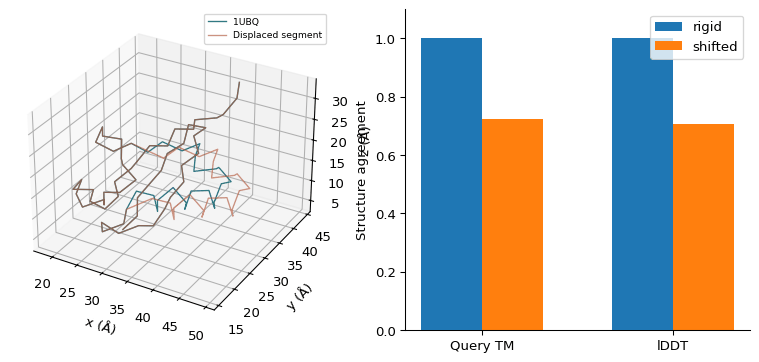

In [2]:
lines = (here / "ubiquitin_atoms.pdb").read_text().splitlines()
atom = [line for line in lines if line.startswith("ATOM")]
xyz = np.array([[float(line[s : s + 8]) for s in [30, 38, 46]] for line in atom])
ids = np.array([int(line[22:26]) for line in atom])
ca = np.array([line[12:16].strip() == "CA" for line in atom])
rotation = Rotation.from_euler("xyz", [0.4, -0.6, 0.7]).as_matrix()
rigid = xyz @ rotation + [7, -12, 4]
deformed = xyz.copy()
deformed[(ids >= 23) & (ids <= 43)] += [7.0, -6.0, 5.0]


def save(path, coords):
    path.write_text(
        "\n".join(
            line[:30] + "".join(f"{v:8.3f}" for v in point) + line[54:]
            for line, point in zip(atom, coords)
        )
        + "\nEND\n"
    )


with TemporaryDirectory() as where:
    work = Path(where)
    targets = work / "targets"
    targets.mkdir()
    save(targets / "rigid.pdb", rigid)
    save(targets / "shifted.pdb", deformed)
    out = work / "hits.tsv"
    cmd = [
        "foldseek",
        "easy-search",
        str(here / "ubiquitin_atoms.pdb"),
        str(targets),
        str(out),
        str(work / "scratch"),
        "--threads",
        "1",
        "--exhaustive-search",
        "1",
        "-e",
        "100",
        "--format-output",
        "query,target,alnlen,qtmscore,lddt",
    ]
    subprocess.run(cmd, check=True, capture_output=True, text=True, timeout=90)
    rows = list(csv.reader(out.read_text().splitlines(), delimiter="\t"))
scores = {}
for query, target, length, tm, lddt in rows:
    name = next(label for label in ["rigid", "shifted"] if target.startswith(label))
    scores[name] = (int(length), float(tm), float(lddt))
print("target     aligned    query TM      lDDT")
for k, v in scores.items():
    print(f"{k:8} {v[0]:8d} {v[1]:11.4f} {v[2]:9.4f}")
assert (
    set(scores) == {"rigid", "shifted"}
    and scores["rigid"][1] > 0.98
    and scores["rigid"][1] > scores["shifted"][1]
)
fig = plt.figure(figsize=(8, 3.7), constrained_layout=True)
a = fig.add_subplot(121, projection="3d")
a.plot(*xyz[ca].T, color="#317982", lw=1, label="1UBQ")
a.plot(*deformed[ca].T, color="#b65b3f", alpha=0.65, lw=1, label="Displaced segment")
a.legend(fontsize=7)
a.set(xlabel="x (Å)", ylabel="y (Å)", zlabel="z (Å)")
b = fig.add_subplot(122)
xx = np.arange(2)
for j, (k, v) in enumerate(sorted(scores.items())):
    b.bar(xx + 0.16 * (2 * j - 1), v[1:], width=0.32, label=k)
b.set(xticks=xx, xticklabels=["Query TM", "lDDT"], ylim=(0, 1.1), ylabel="Structure agreement")
b.legend()
plt.show()

## Interpreting the result

A rigid transformation should preserve geometry apart from PDB coordinate rounding. The two targets have identical residue sequences, so their difference probes the influence of structure. This two-target test does not benchmark search speed or homology detection.

## Exercise

Change the displaced segment length and compare query-normalised TM-score with local distance agreement.

## References

[van Kempen et al., Foldseek](https://pubmed.ncbi.nlm.nih.gov/37156916/)

[Foldseek command-line documentation and licence](https://github.com/steineggerlab/foldseek)

[Vijay-Kumar, Bugg and Cook, ubiquitin structure (1987)](https://doi.org/10.1016/0022-2836(87)90679-6)

[PDB entry 1UBQ](https://www.rcsb.org/structure/1UBQ)

[wwPDB data usage and CC0 dedication](https://www.wwpdb.org/about/usage-policies)